<a href="https://colab.research.google.com/github/adonaytetemke-wq/cofolding-benchmark/blob/main/notebooks/02_esm2_embeddings.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Stage 2: Does a Protein Language Model "Notice" What Makes COX-2 Different?
**Project:** Can AI predict how drugs bind? Benchmarking AI structure and co-folding models on COX enzymes.

Stage 1 showed AI can reproduce the *structures* of COX-1 and COX-2. Stage 2 goes one level deeper: **what does the model actually know about the sequences?**

We use **ESM-2**, a protein language model trained only on sequences. It turns every amino acid into a vector (an *embedding*) that summarizes its context. We ask four questions:
1. At aligned positions, which residues does the model treat as most different between COX-1 and COX-2? Does it single out the selectivity positions **513 and 523**?
2. Are **drug-pocket residues** treated as more conserved than the rest?
3. Does the model separate protein *families* and *orthologs* (same enzyme, different species) correctly?
4. Can the model's attention predict real 3D contacts, checked against the crystal structures?

**Runtime:** a T4 GPU is best (Runtime → Change runtime type). If memory is tight, switch `MODEL` in section 3 to the smaller version.

## 1. Setup

In [1]:
!pip install -q transformers biopython pandas matplotlib requests
import torch
print("GPU available:", torch.cuda.is_available())

GPU available: True


In [2]:
import os, requests
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from Bio import Align
from Bio.Align import substitution_matrices
from Bio.PDB import PDBParser

THREE2ONE = {"ALA":"A","ARG":"R","ASN":"N","ASP":"D","CYS":"C","GLN":"Q","GLU":"E","GLY":"G","HIS":"H",
             "ILE":"I","LEU":"L","LYS":"K","MET":"M","PHE":"F","PRO":"P","SER":"S","THR":"T","TRP":"W",
             "TYR":"Y","VAL":"V","MSE":"M"}
SKIP = {"HOH","HEM","NAG","BMA","MAN","FUC","GOL","SO4","EDO","BOG","NA","CA","CL"}

def xyz(ls):
    return np.array([[float(l[30:38]), float(l[38:46]), float(l[46:54])] for l in ls])

def seq_of(residues):
    return "".join(THREE2ONE.get(r.get_resname(), "X") for r in residues)

exact = Align.PairwiseAligner()
exact.mode = "global"
exact.match_score, exact.mismatch_score = 2, -1
exact.open_gap_score, exact.extend_gap_score = -5, -0.5
exact.end_gap_score = 0.0

def align_pairs(a, b, aligner=exact):
    aln = aligner.align(a, b)[0]
    pairs = []
    for (a0, a1), (b0, b1) in zip(*aln.aligned):
        pairs += list(zip(range(a0, a1), range(b0, b1)))
    return pairs

## 2. Load sequences, structures, and pocket residues
Same entries as Stage 1: COX-1 (1EQG, ibuprofen) and COX-2 (3LN1, celecoxib). Residues within 6 Å of the crystal drug are called **pocket residues**.

In [3]:
def load_experimental(key, pdb_id, prefer, cutoff=6.0):
    text = requests.get(f"https://files.rcsb.org/download/{pdb_id}.pdb", timeout=30).text
    lines = text.splitlines()
    groups = {}
    for l in lines:
        if l.startswith("HETATM") and l[16] in " A" and l[17:20].strip() not in SKIP:
            groups.setdefault((l[17:20].strip(), l[21]), []).append(l)
    choice = next((k for p in prefer for k in groups if k[0] == p), None) or max(groups, key=lambda k: len(groups[k]))
    lig_name, chain_id = choice
    lig = groups[choice]
    seq = "".join(THREE2ONE.get(r, "X") for l in lines if l.startswith("SEQRES") and l[11] == chain_id
                  for r in l[19:].split())
    atoms = [l for l in lines if l.startswith("ATOM") and l[21] == chain_id and l[16] in " A"]
    open(f"exp_{key}.pdb", "w").write("\n".join(atoms) + "\nEND\n")
    s = PDBParser(QUIET=True).get_structure(key, f"exp_{key}.pdb")
    res = [r for r in s[0][chain_id] if r.id[0] == " " and "CA" in r]
    pairs = align_pairs(seq, seq_of(res))
    res_to_seq = {e: si for si, e in pairs}
    lig_xyz = xyz(lig)
    pocket = set()
    for ei, r in enumerate(res):
        if ei not in res_to_seq:
            continue
        heavy = np.array([a.coord for a in r if not a.get_id().startswith("H")])
        if np.linalg.norm(heavy[:, None, :] - lig_xyz[None, :, :], axis=2).min() < cutoff:
            pocket.add(res_to_seq[ei])
    resseq_to_seq = {res[e].id[1]: si for e, si in res_to_seq.items()}
    return {"key": key, "pdb_id": pdb_id, "lig_name": lig_name, "seq": seq, "res": res,
            "res_to_seq": res_to_seq, "resseq_to_seq": resseq_to_seq, "pocket": pocket}

EXP = {"cox1": load_experimental("cox1", "1EQG", ["IBP"]),
       "cox2": load_experimental("cox2", "3LN1", ["CEL", "S58"])}
for k, e in EXP.items():
    print(f"{k}: {e['pdb_id']} | ligand {e['lig_name']} | length {len(e['seq'])} | pocket residues {len(e['pocket'])}")
s1, s2 = EXP["cox1"]["seq"], EXP["cox2"]["seq"]

cox1: 1EQG | ligand IBP | length 580 | pocket residues 23
cox2: 3LN1 | ligand CEL | length 587 | pocket residues 31


In [4]:
# Align COX-1 to COX-2 so we can compare matching positions
blosum = Align.PairwiseAligner()
blosum.substitution_matrix = substitution_matrices.load("BLOSUM62")
blosum.open_gap_score, blosum.extend_gap_score = -10, -0.5
blosum.end_gap_score = 0.0
pairs12 = align_pairs(s1, s2, blosum)
i1 = np.array([p[0] for p in pairs12]); i2 = np.array([p[1] for p in pairs12])
same = np.array([s1[a] == s2[b] for a, b in pairs12])
print(f"Aligned positions: {len(pairs12)} | identical: {same.mean()*100:.0f}%")

Aligned positions: 568 | identical: 64%


## 3. Load ESM-2
The 650M-parameter model fits on a T4 in half precision. For a quick test or a CPU, use `facebook/esm2_t12_35M_UR50D`.

In [5]:
from transformers import AutoTokenizer, EsmModel
MODEL = "facebook/esm2_t33_650M_UR50D"      # or "facebook/esm2_t12_35M_UR50D" for low memory
device = "cuda" if torch.cuda.is_available() else "cpu"
tok = AutoTokenizer.from_pretrained(MODEL)
esm = EsmModel.from_pretrained(MODEL, add_pooling_layer=False)
if device == "cuda":
    esm = esm.half()
esm = esm.to(device).eval()

@torch.inference_mode()
def embed(seq):
    t = tok(seq, return_tensors="pt", truncation=True, max_length=1022).to(device)
    return esm(**t).last_hidden_state[0, 1:-1].float().cpu().numpy()   # one vector per residue

E1, E2 = embed(s1), embed(s2)
print("Embedding shapes:", E1.shape, E2.shape)

config.json:   0%|          | 0.00/724 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/93.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.61GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/534 [00:00<?, ?it/s]

[transformers] EsmModel LOAD REPORT from: facebook/esm2_t33_650M_UR50D
Key                       | Status     |  | 
--------------------------+------------+--+-
lm_head.dense.weight      | UNEXPECTED |  | 
lm_head.layer_norm.bias   | UNEXPECTED |  | 
lm_head.bias              | UNEXPECTED |  | 
lm_head.dense.bias        | UNEXPECTED |  | 
lm_head.layer_norm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Embedding shapes: (580, 1280) (587, 1280)


## 4. Question 1: which positions does the model see as most different?
For each aligned position we compute the **cosine distance** between the COX-1 and COX-2 vectors (0 = same context, higher = more different). Identical amino acids can still differ, because each vector also encodes the surrounding sequence.

In [6]:
def cosdist(A, B):
    return 1 - (A * B).sum(1) / (np.linalg.norm(A, axis=1) * np.linalg.norm(B, axis=1))

dist = cosdist(E1[i1], E2[i2])
row_of = {int(a): r for r, a in enumerate(i1)}
print(f"Mean distance, identical residues:   {dist[same].mean():.3f}")
print(f"Mean distance, substituted residues: {dist[~same].mean():.3f}")

KEY = (513, 523)
key_rows = {}
for pos in KEY:
    si1 = EXP["cox1"]["resseq_to_seq"].get(pos)
    if si1 is None or si1 not in row_of:
        print(f"Position {pos}: not found/aligned"); continue
    r = row_of[si1]
    key_rows[pos] = r
    pct = 100 * (dist < dist[r]).mean()
    print(f"Position {pos}: COX-1 {s1[i1[r]]} -> COX-2 {s2[i2[r]]} | distance {dist[r]:.3f} | "
          f"more different than {pct:.0f}% of aligned positions")
print("Expected: 513 His->Arg, 523 Ile->Val. If residues differ, the PDB numbering is offset.")

Mean distance, identical residues:   0.028
Mean distance, substituted residues: 0.101
Position 513: COX-1 H -> COX-2 R | distance 0.085 | more different than 75% of aligned positions
Position 523: COX-1 I -> COX-2 V | distance 0.078 | more different than 69% of aligned positions
Expected: 513 His->Arg, 523 Ile->Val. If residues differ, the PDB numbering is offset.


Pocket positions: 23 | mean distance pocket 0.022 vs other 0.055
Difference -0.033 (permutation p = 0.001); negative = pocket treated as MORE conserved


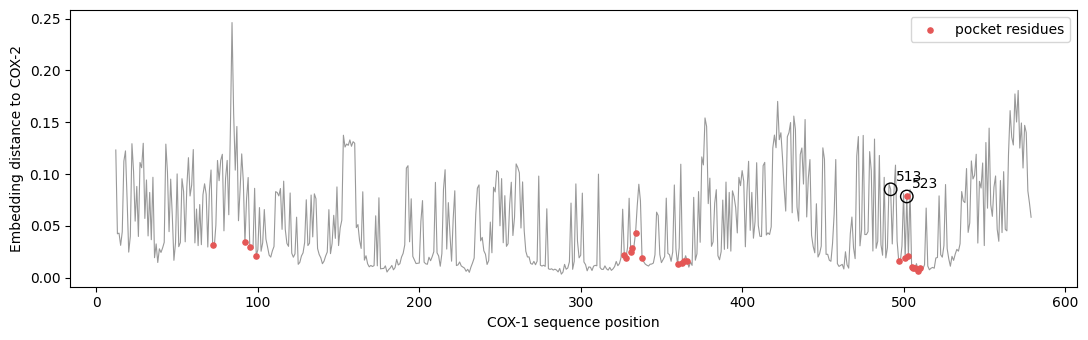

In [7]:
pocket1 = EXP["cox1"]["pocket"]
is_pocket = np.array([int(a) in pocket1 for a in i1])
obs = dist[is_pocket].mean() - dist[~is_pocket].mean()
rng = np.random.default_rng(0)
perm = [(lambda m: dist[m].mean() - dist[~m].mean())(rng.permutation(is_pocket)) for _ in range(5000)]
p_val = float((np.abs(perm) >= abs(obs)).mean())
print(f"Pocket positions: {is_pocket.sum()} | mean distance pocket {dist[is_pocket].mean():.3f} vs other {dist[~is_pocket].mean():.3f}")
print(f"Difference {obs:+.3f} (permutation p = {p_val:.3f}); negative = pocket treated as MORE conserved")

fig, ax = plt.subplots(figsize=(11, 3.5))
ax.plot(i1, dist, color="#999999", lw=0.8)
ax.scatter(i1[is_pocket], dist[is_pocket], s=14, color="#E45756", label="pocket residues", zorder=3)
for pos, r in key_rows.items():
    ax.scatter(i1[r], dist[r], s=80, facecolor="none", edgecolor="black", zorder=4)
    ax.annotate(str(pos), (i1[r], dist[r]), xytext=(4, 6), textcoords="offset points")
ax.set_xlabel("COX-1 sequence position"); ax.set_ylabel("Embedding distance to COX-2")
ax.legend(); plt.tight_layout(); plt.savefig("day2_embedding_difference.png", dpi=150); plt.show()

## 5. Question 3: does the model separate families and species?
We embed a small panel of proteins, average each into one vector, remove the common component shared by all proteins, and compare them. If the model is sensible, **sheep COX-1 should be closest to human COX-1**, and **mouse COX-2 closest to human COX-2**, with unrelated proteins far away.

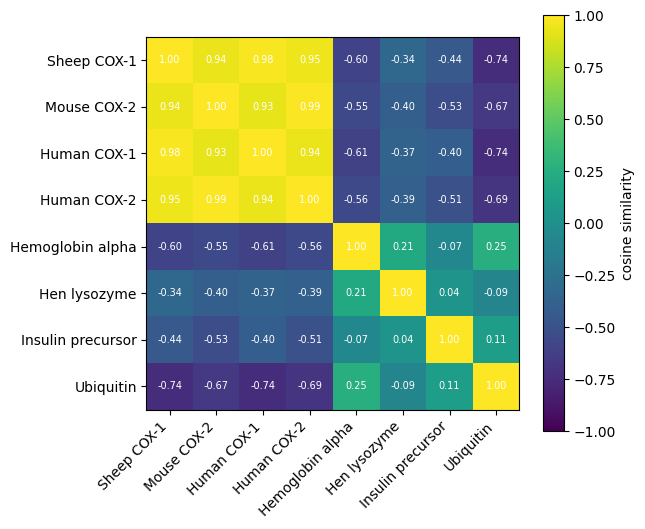

Sheep COX-1: vs human COX-1 (ortholog) 0.9843397736549377 | vs mouse COX-2 (paralog) 0.9394051432609558
Mouse COX-2: vs human COX-2 (ortholog) 0.9886914491653442 | vs sheep COX-1 (paralog) 0.9394051432609558


In [8]:
def uniprot(acc):
    r = requests.get(f"https://rest.uniprot.org/uniprotkb/{acc}.fasta", timeout=30)
    r.raise_for_status()
    return "".join(r.text.splitlines()[1:])

PANEL = {"Sheep COX-1": s1, "Mouse COX-2": s2}
for name, acc in {"Human COX-1": "P23219", "Human COX-2": "P35354", "Hemoglobin alpha": "P69905",
                  "Hen lysozyme": "P00698", "Insulin precursor": "P01308"}.items():
    try:
        PANEL[name] = uniprot(acc)
    except Exception as e:
        print("Skipped", name, "-", e)
PANEL["Ubiquitin"] = "MQIFVKTLTGKTITLEVEPSDTIENVKAKIQDKEGIPPDQQRLIFAGKQLEDGRTLSDYNIQKESTLHLVLRLRGG"

names = list(PANEL)
M = np.array([embed(PANEL[n]).mean(axis=0) for n in names])
M = M - M.mean(axis=0)
Mn = M / np.linalg.norm(M, axis=1, keepdims=True)
S = Mn @ Mn.T

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(S, cmap="viridis", vmin=-1, vmax=1)
ax.set_xticks(range(len(names))); ax.set_xticklabels(names, rotation=45, ha="right")
ax.set_yticks(range(len(names))); ax.set_yticklabels(names)
for a in range(len(names)):
    for b in range(len(names)):
        ax.text(b, a, f"{S[a, b]:.2f}", ha="center", va="center", color="white", fontsize=7)
plt.colorbar(im, label="cosine similarity"); plt.tight_layout()
plt.savefig("day2_similarity.png", dpi=150); plt.show()

def sim(a, b):
    return float(S[names.index(a), names.index(b)]) if a in names and b in names else None
ortho1, para1 = sim("Sheep COX-1", "Human COX-1"), sim("Sheep COX-1", "Mouse COX-2")
ortho2, para2 = sim("Mouse COX-2", "Human COX-2"), sim("Mouse COX-2", "Sheep COX-1")
print("Sheep COX-1: vs human COX-1 (ortholog)", ortho1, "| vs mouse COX-2 (paralog)", para1)
print("Mouse COX-2: vs human COX-2 (ortholog)", ortho2, "| vs sheep COX-1 (paralog)", para2)

## 6. A map of residue space
Every residue of both enzymes, projected to 2 dimensions (PCA). Red outlines are drug-pocket residues.

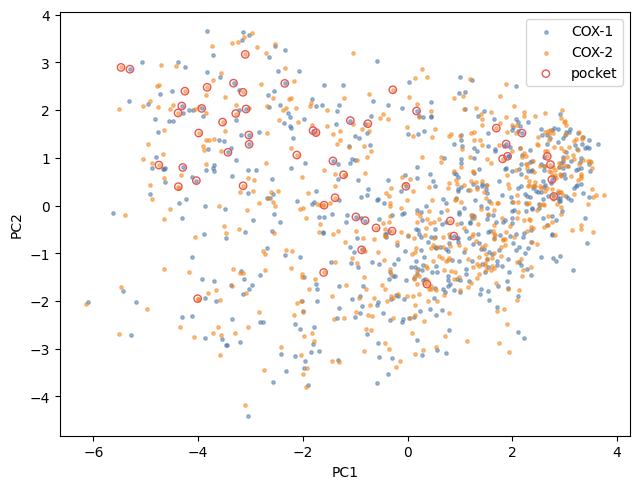

In [9]:
X = np.vstack([E1, E2])
X = X - X.mean(axis=0)
_, _, Vt = np.linalg.svd(X, full_matrices=False)
Z = X @ Vt[:2].T
n1 = len(E1)
pocket_mask = np.zeros(len(X), bool)
pocket_mask[list(EXP["cox1"]["pocket"])] = True
pocket_mask[[n1 + i for i in EXP["cox2"]["pocket"]]] = True

fig, ax = plt.subplots(figsize=(6.5, 5))
ax.scatter(Z[:n1, 0], Z[:n1, 1], s=6, alpha=0.5, color="#4C78A8", label="COX-1")
ax.scatter(Z[n1:, 0], Z[n1:, 1], s=6, alpha=0.5, color="#F58518", label="COX-2")
ax.scatter(Z[pocket_mask, 0], Z[pocket_mask, 1], s=28, facecolor="none", edgecolor="#E45756", label="pocket")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.legend(); plt.tight_layout()
plt.savefig("day2_pca.png", dpi=150); plt.show()

## 7. Question 4: can the model's attention predict real 3D contacts?
ESM-2 was never shown a structure, but its attention patterns can be turned into a contact map. We check the top predicted long-range contacts against the crystal structures (contact = side-chain atoms within 8 Å, residues at least 24 apart in sequence). This cell is optional and is skipped if the contact head is unavailable.

In [10]:
def predict_contacts(seq):
    t = tok(seq, return_tensors="pt").to(device)
    with torch.inference_mode():
        P = esm.predict_contacts(t["input_ids"], t["attention_mask"])
    P = P[0].float().cpu().numpy()
    assert P.shape[0] == len(seq), f"unexpected shape {P.shape}"
    return P

def contact_precision(key):
    info = EXP[key]
    try:
        P = predict_contacts(info["seq"])
    except Exception as e:
        print(key, "contact prediction skipped:", e)
        return None, None
    es = np.array(list(info["res_to_seq"].keys())); sis = np.array([info["res_to_seq"][e] for e in es])
    C = np.array([(info["res"][e]["CB"] if "CB" in info["res"][e] else info["res"][e]["CA"]).coord for e in es])
    true = np.linalg.norm(C[:, None, :] - C[None, :, :], axis=2) < 8.0
    probs = P[np.ix_(sis, sis)]
    iu = np.triu_indices(len(es), k=1)
    mask = np.abs(sis[:, None] - sis[None, :])[iu] >= 24
    pv, tv = probs[iu][mask], true[iu][mask]
    top = np.argsort(-pv)[: max(1, len(info["seq"]) // 5)]
    return float(tv[top].mean()), float(tv.mean())

CONTACT = {k: contact_precision(k) for k in EXP}
for k, (prec, base) in CONTACT.items():
    if prec is not None:
        print(f"{k}: precision of top L/5 long-range contacts = {prec*100:.0f}% (random baseline {base*100:.1f}%)")

[transformers] `sdpa` attention does not support `output_attentions=True`. Please set your attention to `eager` if you want any of these features.


cox1 contact prediction skipped: stack expects a non-empty TensorList
cox2 contact prediction skipped: stack expects a non-empty TensorList


## 8. Summary for your README

In [11]:
rows = [
    ("Aligned positions / identity", f"{len(pairs12)} / {same.mean()*100:.0f}%"),
    ("Mean embedding distance: identical vs substituted", f"{dist[same].mean():.3f} vs {dist[~same].mean():.3f}"),
]
for pos, r in key_rows.items():
    rows.append((f"Position {pos} ({s1[i1[r]]}->{s2[i2[r]]}) percentile", f"{100*(dist < dist[r]).mean():.0f}"))
rows += [
    ("Pocket vs other distance", f"{dist[is_pocket].mean():.3f} vs {dist[~is_pocket].mean():.3f} (p={p_val:.3f})"),
    ("COX-1 sheep: ortholog vs paralog similarity", f"{ortho1} vs {para1}"),
    ("COX-2 mouse: ortholog vs paralog similarity", f"{ortho2} vs {para2}"),
]
for k, (prec, base) in CONTACT.items():
    if prec is not None:
        rows.append((f"{k} top-L/5 contact precision", f"{prec*100:.0f}% (baseline {base*100:.1f}%)"))
summary = pd.DataFrame(rows, columns=["Metric", "Value"])
summary.to_csv("day2_summary.csv", index=False)
print("| Metric | Value |\n|---|---|")
for m, v in rows:
    print(f"| {m} | {v} |")

| Metric | Value |
|---|---|
| Aligned positions / identity | 568 / 64% |
| Mean embedding distance: identical vs substituted | 0.028 vs 0.101 |
| Position 513 (H->R) percentile | 75 |
| Position 523 (I->V) percentile | 69 |
| Pocket vs other distance | 0.022 vs 0.055 (p=0.001) |
| COX-1 sheep: ortholog vs paralog similarity | 0.9843397736549377 vs 0.9394051432609558 |
| COX-2 mouse: ortholog vs paralog similarity | 0.9886914491653442 vs 0.9394051432609558 |


## What to write in your README
- Did the model treat the selectivity positions (513, 523) as unusually different, or as ordinary? Report the percentile whichever way it falls.
- Were pocket residues more conserved in the model's view than the rest? Is the p-value convincing?
- Did the panel separate orthologs from paralogs the way biology says it should?
- How good was attention-based contact prediction compared with random?

## Limitations
- Embeddings summarize sequence context. They are **not** structures and not binding energies.
- A cosine distance is a relative score, not a measure of functional difference.
- ESM-2 was trained on large sequence databases that almost certainly include COX proteins.
- Pocket residues come from one crystal ligand per enzyme.
- Selectivity positions assume the PDB numbering matches the standard COX numbering (check the printed residue names).

## Next (Stage 3)
Co-folding: predict the drug and the protein together from sequence and chemistry alone.